# 5 · Utility, risk aversion and Value-at-Risk: from preferences to risk limits
Two ways of saying "how much risk is acceptable" sit side by side in finance. **Utility theory** describes what an investor *wants*: how much expected return they will give up to avoid uncertainty. **Value-at-Risk (VaR) and Expected Shortfall (ES)** describe what a risk manager will *allow*: how large a loss can be tolerated with a given confidence. This notebook builds both from first principles and connects them on real data (SPY and a 12-stock portfolio, 2012-2026).

1. Utility functions, certainty equivalents and the risk premium
2. Measuring risk aversion: absolute vs relative (CARA vs CRRA)
3. Mean-variance utility and the optimal amount of risk
4. VaR and ES: parametric, historical, and why ES is the better risk measure
5. Translating a VaR limit into a risk-aversion level, and back

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
prices = pd.read_csv("../data/prices.csv", index_col=0, parse_dates=True)

## 1. Utility, certainty equivalent and risk premium
A risk-averse investor has a **concave** utility of wealth $u(W)$. Faced with a gamble, they value it at its **certainty equivalent** (CE): the sure amount with the same expected utility, $u(CE)=E[u(W)]$. The gap $E[W]-CE$ is the **risk premium**, the most they would pay to remove the risk.

Example: wealth \$100,000 and a coin-flip that adds or subtracts \$40,000.

In [2]:
W0, h = 100_000, 40_000
outcomes, probs = np.array([W0 - h, W0 + h]), np.array([.5, .5])
def crra(w, g):
    w = np.asarray(w, dtype=float); return np.log(w) if g == 1 else (w ** (1 - g) - 1) / (1 - g)
def crra_inv(u, g): return np.exp(u) if g == 1 else (u * (1 - g) + 1) ** (1 / (1 - g))
rows = []
for g in [1e-6, 0.5, 1, 2, 5, 10]:
    eu = (probs * crra(outcomes / W0, g)).sum(); ce = W0 * crra_inv(eu, g)   # CRRA is scale-free: work in units of initial wealth
    rows.append({"relative risk aversion γ": round(g, 1) if g > 0.001 else 0.0, "certainty equivalent $": ce, "risk premium $": W0 - ce, "premium % of stake": 100 * (W0 - ce) / h})
pd.DataFrame(rows).round({"certainty equivalent $": 0, "risk premium $": 0, "premium % of stake": 1})

,relative risk aversion γ,certainty equivalent $,risk premium $,premium % of stake
0,0.0,100000.0,0.0,0.0
1,0.5,95826.0,4174.0,10.4
2,1.0,91652.0,8348.0,20.9
3,2.0,84000.0,16000.0,40.0
4,5.0,70763.0,29237.0,73.1
5,10.0,64800.0,35200.0,88.0


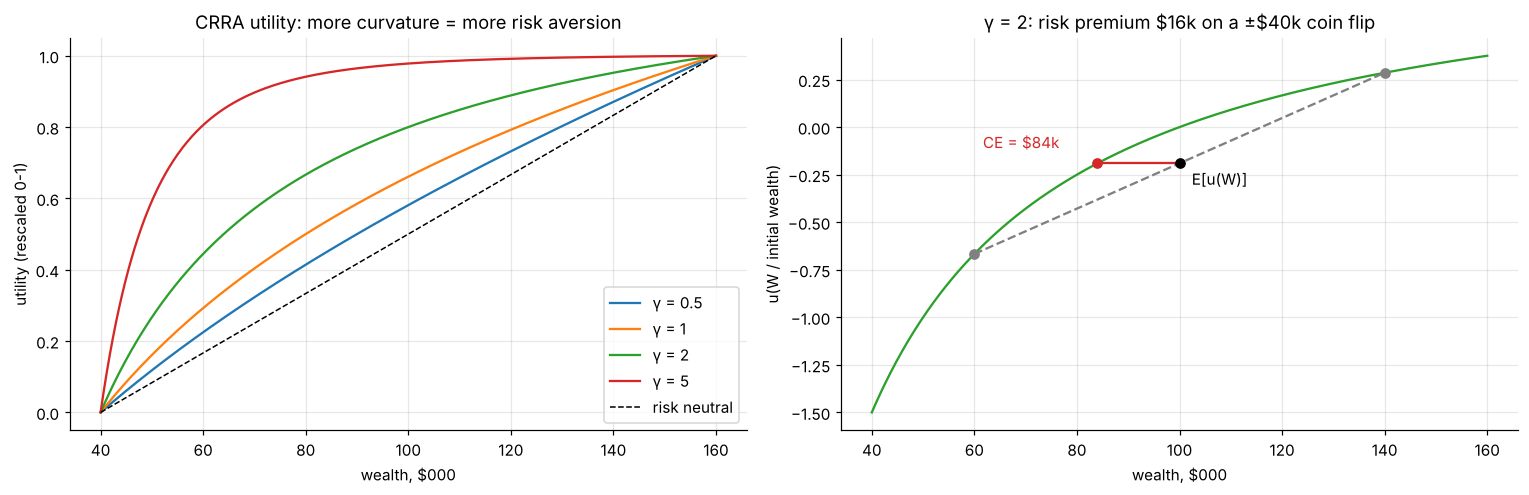

In [3]:
w = np.linspace(40_000, 160_000, 400)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for g in [0.5, 1, 2, 5]:
    u = crra(w / W0, g); u = (u - u.min()) / (u.max() - u.min()); axes[0].plot(w / 1e3, u, label=f"γ = {g}")
axes[0].plot(w / 1e3, (w - w.min()) / (w.max() - w.min()), "k--", lw=1, label="risk neutral")
axes[0].set_xlabel("wealth, \$000"); axes[0].set_ylabel("utility (rescaled 0-1)"); axes[0].set_title("CRRA utility: more curvature = more risk aversion"); axes[0].legend()
g = 2; uL, uH = crra(outcomes[0] / W0, g), crra(outcomes[1] / W0, g); eu = (uL + uH) / 2; ce = W0 * crra_inv(eu, g)
axes[1].plot(w / 1e3, crra(w / W0, g), c="C2"); axes[1].plot(outcomes / 1e3, [uL, uH], "o--", c="grey")
axes[1].scatter([W0 / 1e3], [eu], c="k", zorder=3); axes[1].scatter([ce / 1e3], [eu], c="C3", zorder=3)
axes[1].annotate("E[u(W)]", (W0 / 1e3, eu), xytext=(8, -14), textcoords="offset points")
axes[1].annotate(f"CE = \${ce / 1e3:.0f}k", (ce / 1e3, eu), xytext=(-75, 10), textcoords="offset points", color="C3")
axes[1].hlines(eu, ce / 1e3, W0 / 1e3, colors="C3"); axes[1].set_title(f"γ = 2: risk premium \${(W0 - ce) / 1e3:.0f}k on a ±\$40k coin flip")
axes[1].set_xlabel("wealth, \$000"); axes[1].set_ylabel("u(W / initial wealth)")
plt.tight_layout(); plt.savefig(IMG / "utility_certainty_equivalent.png", bbox_inches="tight"); plt.show()

## 2. Absolute vs relative risk aversion
* **Absolute** risk aversion $A(W)=-u''(W)/u'(W)$: aversion to a gamble of a fixed **dollar** size.
* **Relative** risk aversion $R(W)=W\,A(W)$: aversion to a gamble of a fixed **percentage** of wealth.

CARA utility $u=-e^{-aW}$ has constant $A$, so a millionaire would pay the same to avoid a \$1,000 bet as a student, which is implausible. CRRA has constant $R$: wealthier investors take the same *proportional* risks. That is why CRRA (and its mean-variance approximation) is the workhorse of portfolio theory.

In [4]:
rows = []
for W in [50_000, 100_000, 500_000, 2_000_000]:
    out = {"wealth $": W}
    for name, u, ui in [("CARA a=2e-5", lambda x: -np.exp(-2e-5 * x), lambda v: -np.log(-v) / 2e-5), ("CRRA γ=2", lambda x: crra(x, 2), lambda v: crra_inv(v, 2))]:
        eu = 0.5 * u(W - 10_000) + 0.5 * u(W + 10_000); out[f"premium for ±$10k, {name}"] = W - ui(eu)
        eu = 0.5 * u(W * 0.8) + 0.5 * u(W * 1.2); out[f"premium for ±20%, {name} (% of W)"] = 100 * (W - ui(eu)) / W
    rows.append(out)
pd.DataFrame(rows).round(2)

,wealth $,"premium for ±$10k, CARA a=2e-5","premium for ±20%, CARA a=2e-5 (% of W)","premium for ±$10k, CRRA γ=2","premium for ±20%, CRRA γ=2 (% of W)"
0,50000,993.4,1.99,2000.0,4.0
1,100000,993.4,3.90,1000.0,4.0
2,500000,993.4,13.25,200.0,4.0
3,2000000,993.4,18.27,50.0,4.0


## 3. Mean-variance utility and the optimal risky share
For normally distributed returns (or small risks), CRRA utility is well approximated by

$$U = E[r_p] - \tfrac{A}{2}\,\sigma_p^2$$

With a risk-free asset at $r_f$ and a risky portfolio with excess return $\mu-r_f$ and volatility $\sigma$, maximising $U$ over the share $w$ in the risky asset gives

$$w^*=\frac{\mu-r_f}{A\,\sigma^2}$$

The same formula is Merton's (1969) solution. Below, the "risky asset" is SPY, with inputs estimated on 2012-2026 data.

In [5]:
r = np.log(prices).diff().dropna()
spy = r["SPY"]
mu, sig = spy.mean() * 252, spy.std() * np.sqrt(252); rf = 0.03
print(f"SPY 2012-2026: mean log return {mu:.1%}, volatility {sig:.1%}; assumed risk-free {rf:.0%}; Sharpe {(mu - rf) / sig:.2f}")
A_grid = [1, 2, 3, 4, 6, 8, 10]
alloc = pd.DataFrame({"risk aversion A": A_grid, "optimal SPY share w*": [(mu - rf) / (a * sig ** 2) for a in A_grid]})
alloc["portfolio volatility"] = alloc["optimal SPY share w*"] * sig
alloc["certainty-equivalent return"] = rf + alloc["optimal SPY share w*"] * (mu - rf) - 0.5 * np.array(A_grid) * alloc["portfolio volatility"] ** 2
alloc.round(3)

SPY 2012-2026: mean log return 13.8%, volatility 16.6%; assumed risk-free 3%; Sharpe 0.65


,risk aversion A,optimal SPY share w*,portfolio volatility,certainty-equivalent return
0,1,3.924,0.650,0.241
1,2,1.962,0.325,0.136
2,3,1.308,0.217,0.100
3,4,0.981,0.162,0.083
4,6,0.654,0.108,0.065
5,8,0.490,0.081,0.056
6,10,0.392,0.065,0.051


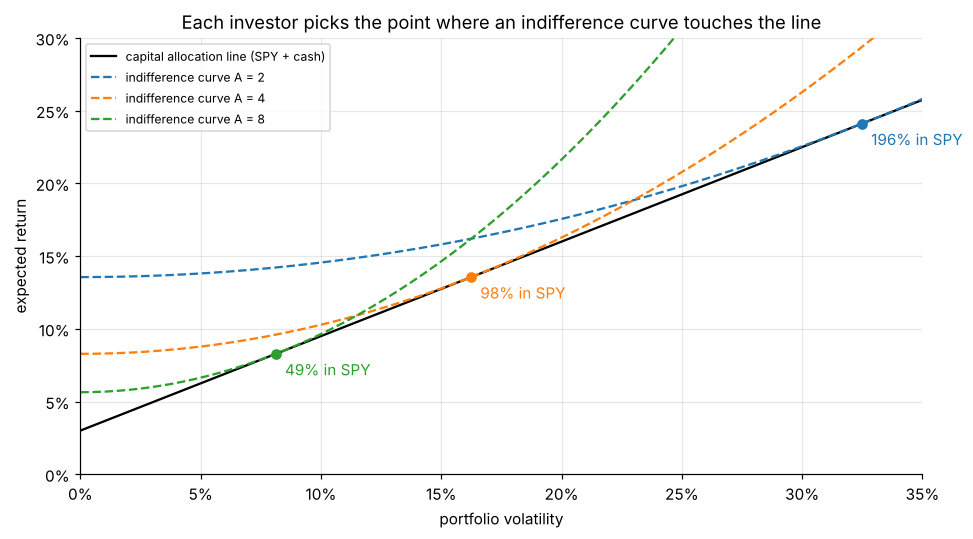

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
s = np.linspace(0, 0.35, 200)
ax.plot(s, rf + (mu - rf) / sig * s, "k", lw=1.5, label="capital allocation line (SPY + cash)")
for a, c in [(2, "C0"), (4, "C1"), (8, "C2")]:
    w_ = (mu - rf) / (a * sig ** 2); U = rf + w_ * (mu - rf) - 0.5 * a * (w_ * sig) ** 2
    ax.plot(s, U + 0.5 * a * s ** 2, c, ls="--", label=f"indifference curve A = {a}")
    ax.scatter([w_ * sig], [rf + w_ * (mu - rf)], c=c, zorder=3)
    ax.annotate(f"{w_:.0%} in SPY", (w_ * sig, rf + w_ * (mu - rf)), xytext=(6, -14), textcoords="offset points", color=c)
ax.set_xlim(0, .35); ax.set_ylim(0, .3); ax.set_xlabel("portfolio volatility"); ax.set_ylabel("expected return")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Each investor picks the point where an indifference curve touches the line"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "indifference_curves.png", bbox_inches="tight"); plt.show()

## 4. Value-at-Risk and Expected Shortfall
For a loss $L$ over a horizon and confidence $\alpha$:
* $\text{VaR}_\alpha$ is the loss exceeded only with probability $1-\alpha$ (a quantile).
* $\text{ES}_\alpha=E[L\mid L\ge \text{VaR}_\alpha]$ is the average loss *in* the tail.

Below, a \$1m position in SPY and an equal-weight portfolio of the 12 stocks, with one-day horizon, estimated by Normal, Student-t and historical methods.

In [7]:
stocks = [c for c in prices if c != "SPY"]
port = r[stocks].mean(axis=1)
def var_es(x, a=0.99, value=1e6):
    L = -x.values
    mu_, sd = L.mean(), L.std(ddof=1); z = stats.norm.ppf(a)
    nu, loc, sc = stats.t.fit(L); q = stats.t.ppf(a, nu)
    hv = np.quantile(L, a)
    return {"Normal VaR": mu_ + sd * z, "Normal ES": mu_ + sd * stats.norm.pdf(z) / (1 - a),
            "Student-t VaR": loc + sc * q, "Student-t ES": loc + sc * stats.t.pdf(q, nu) / (1 - a) * (nu + q ** 2) / (nu - 1),
            "Historical VaR": hv, "Historical ES": L[L >= hv].mean()}
tab = pd.DataFrame({"SPY": var_es(spy), "12-stock equal weight": var_es(port)}) * 1e6
print("one-day 99% VaR and ES on a $1,000,000 position ($):")
tab.round(0)

one-day 99% VaR and ES on a $1,000,000 position ($):


,SPY,12-stock equal weight
Normal VaR,23720.0,24275.0
Normal ES,27255.0,27904.0
Student-t VaR,28223.0,28217.0
Student-t ES,44919.0,44413.0
Historical VaR,30250.0,31207.0
Historical ES,43992.0,45705.0


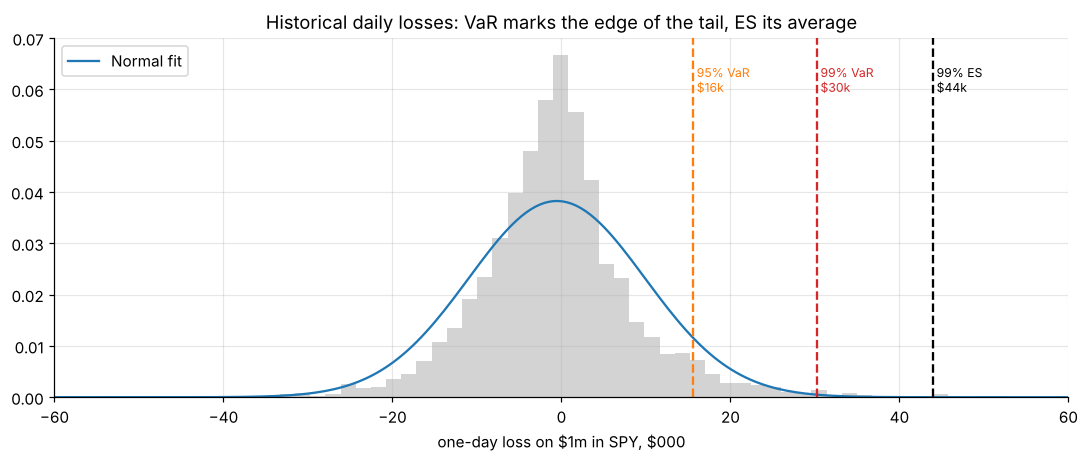

In [8]:
L = -spy.values * 1e6
v95, v99 = np.quantile(L, [.95, .99]); es99 = L[L >= v99].mean()
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.hist(L / 1e3, bins=120, color="lightgrey", density=True)
x = np.linspace(L.min(), L.max(), 400); ax.plot(x / 1e3, stats.norm.pdf(x, L.mean(), L.std()) * 1e3, "C0", label="Normal fit")
for val, lab, c in [(v95, "95% VaR", "C1"), (v99, "99% VaR", "C3"), (es99, "99% ES", "k")]:
    ax.axvline(val / 1e3, color=c, ls="--"); ax.text(val / 1e3, ax.get_ylim()[1] * .85, f" {lab}\n \${val / 1e3:.0f}k", color=c, fontsize=8)
ax.set_xlim(-60, 60); ax.set_xlabel("one-day loss on \$1m in SPY, \$000"); ax.set_title("Historical daily losses: VaR marks the edge of the tail, ES its average")
ax.legend(); plt.tight_layout(); plt.savefig(IMG / "var_es_tail.png", bbox_inches="tight"); plt.show()

### Why regulators moved from VaR to ES: VaR is not subadditive
A risk measure should reward diversification: the risk of A+B should not exceed risk(A) + risk(B). VaR can break this. Take two independent loans of \$100 each, each with a 4% chance of total loss. At 95% confidence:

In [9]:
p = 0.04
single = stats.binom(1, p); pair = stats.binom(2, p)
def var_disc(dist, a, size): 
    k = 0
    while dist.cdf(k) < a: k += 1
    return k * size
def es_disc(dist, a, size, n):
    ks = np.arange(n + 1); pk = dist.pmf(ks); var_k = var_disc(dist, a, 1)
    # tail of probability (1-a): full mass above VaR plus the needed fraction at VaR
    above = pk[ks > var_k].sum(); frac = ((1 - a) - above) / pk[var_k]
    return size * ((ks[ks > var_k] * pk[ks > var_k]).sum() + frac * var_k * pk[var_k]) / (1 - a)
print(f"VaR 95%: one loan {var_disc(single, .95, 100)}, two loans held together {var_disc(pair, .95, 100)}  -> diversification 'increases' VaR")
print(f"ES 95% : one loan {es_disc(single, .95, 100, 1):.0f}, two loans {es_disc(pair, .95, 100, 2):.0f}, sum of standalone ES {2 * es_disc(single, .95, 100, 1):.0f}  -> ES is subadditive")

VaR 95%: one loan 0, two loans held together 100  -> diversification 'increases' VaR
ES 95% : one loan 80, two loans 103, sum of standalone ES 160  -> ES is subadditive


## 5. From a VaR limit to an allocation, and back to risk aversion
A board sets a limit such as "one-day 99% VaR no more than 1.5% of the portfolio". What share of SPY does that permit, and what risk aversion does the limit imply? Under normality, $\text{VaR}_{99}(w)\approx z_{0.99}\,w\,\sigma_d-w\,\mu_d$, so the maximum share is $w=\text{limit}/(z\sigma_d-\mu_d)$. The implied $A$ follows by inverting $w^*=(\mu-r_f)/(A\sigma^2)$.

In [10]:
sd_d, mu_d = spy.std(), spy.mean(); z = stats.norm.ppf(0.99)
hist_var_unit = np.quantile(-spy, 0.99)
rows = []
for limit in [0.005, 0.01, 0.015, 0.02, 0.03]:
    w_norm = limit / (z * sd_d - mu_d); w_hist = limit / hist_var_unit
    rows.append({"VaR limit (% of portfolio)": 100 * limit, "max SPY share (Normal)": w_norm, "max SPY share (historical)": w_hist,
                 "implied risk aversion A": (mu - rf) / (w_hist * sig ** 2)})
lim = pd.DataFrame(rows); lim.round(2)

,VaR limit (% of portfolio),max SPY share (Normal),max SPY share (historical),implied risk aversion A
0,0.5,0.21,0.17,23.74
1,1.0,0.42,0.33,11.87
2,1.5,0.63,0.50,7.91
3,2.0,0.84,0.66,5.94
4,3.0,1.26,0.99,3.96


In [11]:
exc = (-spy > hist_var_unit).astype(int)
yearly = exc.groupby(exc.index.year).agg(["sum", "size"])
yearly["expected"] = (yearly["size"] * 0.01).round(1)
print("99% VaR breaches per year for a full SPY position (expected about 2.5 a year):")
yearly.rename(columns={"sum": "breaches", "size": "trading days"}).T

99% VaR breaches per year for a full SPY position (expected about 2.5 a year):


Date,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
breaches,0.0,0.0,0.0,3.0,1.0,0.0,5.0,1.0,15.0,0.0,8.0,0.0,1.0,3.0,1.0
trading days,249.0,252.0,252.0,252.0,252.0,251.0,251.0,252.0,253.0,252.0,251.0,250.0,252.0,250.0,217.0
expected,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.5,2.2


## Findings
* **Risk aversion has a price.** On a ±\$40,000 coin flip with \$100,000 of wealth, a risk-neutral investor pays nothing to avoid the bet. The premium is about \$8,300 with log utility (γ = 1), \$16,000 at γ = 2 about \$29,000 at γ = 5 and \$35,000 at γ = 10.
* **CRRA, not CARA, matches behaviour.** Under CARA the premium for a \$10,000 gamble is about \$993 whether wealth is \$50k or \$2m. Under CRRA (γ = 2) it falls from \$2,000 to \$50 as wealth grows, while the premium for a ±20% gamble stays at 4% of wealth. That scale-independence is why CRRA and its mean-variance form underpin portfolio choice.
* **On 2012-2026 SPY data** (13.8% mean log return, 16.6% volatility, a strong period), the mean-variance optimum is about 98% in equities at A = 4, 49% at A = 8 and a *levered* 196% at A = 2. These inputs are in-sample; forward-looking estimates would be lower, so the optimal shares would be too.
* **Normal VaR understates tail risk.** For \$1m in SPY, one-day 99% ES is about \$44,000 historically vs \$27,000 under a Normal assumption. Student-t captures the fat tail (\$45,000), and the equal-weight 12-stock portfolio behaves similarly. VaR also fails subadditivity: two independent 4%-default loans held together *raise* 95% VaR from \$0 to \$100, whereas ES (\$103) stays below the sum of the standalone figures (\$160).
* **Limits and preferences are two views of one dial.** A one-day 99% VaR limit of 1.5% permits about a 50% SPY share on historical data (63% under normality), the same as a mean-variance investor with risk aversion A ≈ 8. A full SPY position breached its 99% VaR 15 times in 2020 and 8 times in 2022 against about 2.5 expected, and never in calm years such as 2017 or 2021. Breaches cluster, which is why VaR models must be backtested (see market-risk-models).